# 03 — Machine Learning: Churn Prediction

Unlike the repeat-purchase problem in the coffee-sales project, this dataset's class balance
(26.5% churn) is reasonable for classification, so a genuinely useful model is a realistic goal
here -- tested honestly below, not assumed.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("../data/cleaned_telco_churn.csv")
print(df.shape)


(7043, 21)


## Feature preparation

Note: an initial run without scaling produced a `ConvergenceWarning` from `LogisticRegression`
-- the solver couldn't converge within 1000 iterations because the 3 continuous columns
(`tenure`, `MonthlyCharges`, `TotalCharges`) sit on wildly different scales than the one-hot
encoded booleans. Fixed by standard-scaling the continuous columns below, which also makes the
resulting coefficients directly comparable to each other for the feature-importance chart later
in this notebook.

In [2]:
y = (df["Churn"] == "Yes").astype(int)

feature_cols = [c for c in df.columns if c not in ("customerID", "Churn")]
X = pd.get_dummies(df[feature_cols], drop_first=True)

# Scale the 3 continuous columns -- they're on wildly different scales than the
# one-hot booleans (tenure 0-72, TotalCharges 0-8600+), which was preventing
# LogisticRegression's solver from converging within a reasonable iteration count.
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print(f"Features: {X.shape[1]} (after one-hot encoding)")
print(f"Churn rate: {y.mean():.1%}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Features: 23 (after one-hot encoding)
Churn rate: 26.5%


## Models

In [3]:
baseline_acc = 1 - y_test.mean()
print(f"Naive 'always predict no churn' baseline accuracy: {baseline_acc:.1%}")
print()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, max_depth=3, random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "cv_roc_auc_mean": cv_scores.mean(),
        "cv_roc_auc_std": cv_scores.std(),
        "y_pred": y_pred, "y_proba": y_proba, "model": model,
    }

results_df = pd.DataFrame({k: {m: v for m, v in r.items() if isinstance(v, (int, float))} for k, r in results.items()}).T
print(results_df.round(4))


Naive 'always predict no churn' baseline accuracy: 73.5%

                     accuracy  precision  ...  cv_roc_auc_mean  cv_roc_auc_std
Logistic Regression    0.7501     0.5188  ...           0.8449          0.0135
Random Forest          0.7660     0.5419  ...           0.8441          0.0112
Gradient Boosting      0.7956     0.6507  ...           0.8404          0.0096

[3 rows x 7 columns]


## Evaluation

Best model by cross-validated ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

    No churn       0.91      0.73      0.81      1294
       Churn       0.52      0.80      0.63       467

    accuracy                           0.75      1761
   macro avg       0.71      0.76      0.72      1761
weighted avg       0.81      0.75      0.76      1761



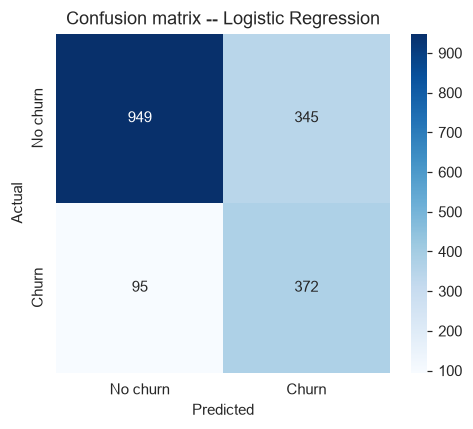

In [4]:
best_name = results_df["cv_roc_auc_mean"].idxmax()
best = results[best_name]
print(f"Best model by cross-validated ROC-AUC: {best_name}")
print(classification_report(y_test, best["y_pred"], target_names=["No churn", "Churn"]))

cm = confusion_matrix(y_test, best["y_pred"])
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix -- {best_name}")
plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=130, bbox_inches="tight")
plt.show()


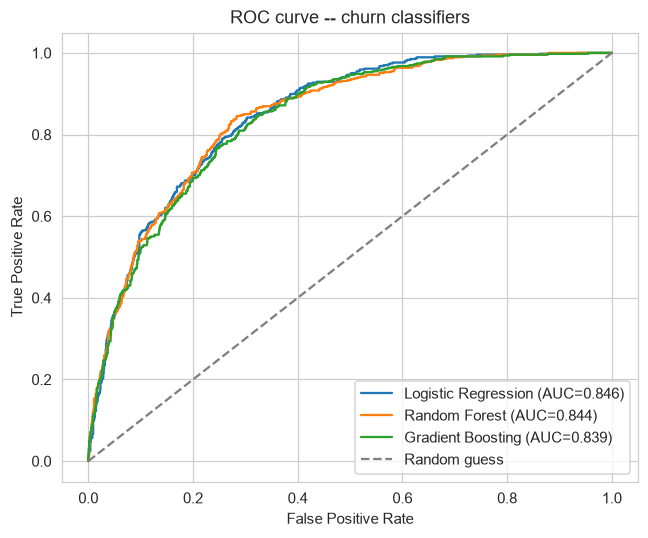

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={r['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve -- churn classifiers")
ax.legend()
plt.tight_layout()
plt.savefig("../images/roc_curve.png", dpi=130, bbox_inches="tight")
plt.show()


Contract_Two year                -1.359
tenure                           -1.163
InternetService_No               -1.133
Contract_One year                -0.722
OnlineSecurity_Yes               -0.382
MonthlyCharges                   -0.342
TechSupport_Yes                  -0.322
Dependents_Yes                   -0.229
SeniorCitizen_Yes                 0.198
MultipleLines_Yes                 0.278
StreamingTV_Yes                   0.291
PaymentMethod_Electronic check    0.371
PaperlessBilling_Yes              0.376
StreamingMovies_Yes               0.379
TotalCharges                      0.517
InternetService_Fiber optic       1.015
dtype: float64


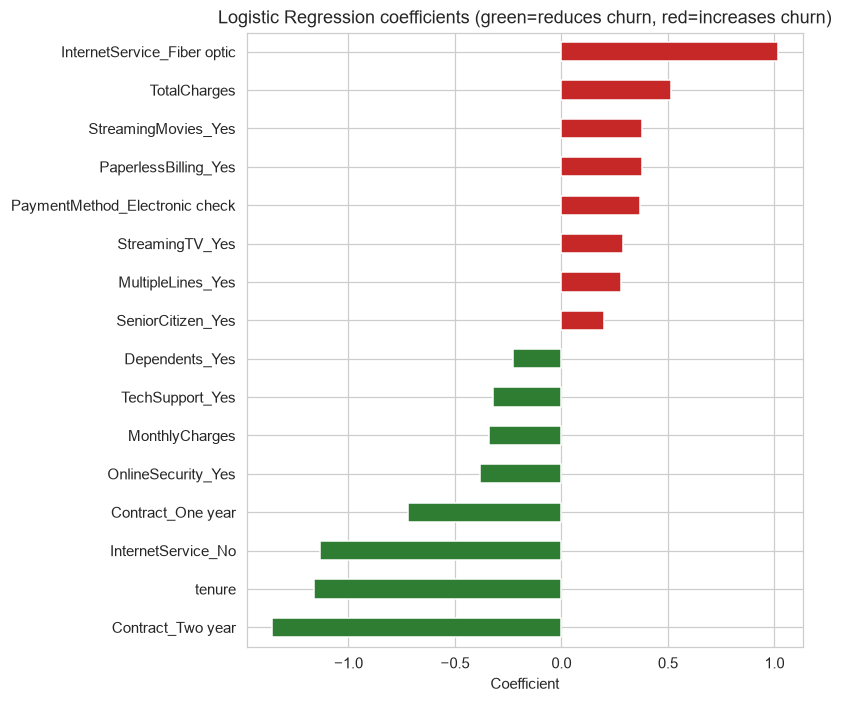

In [6]:
logreg = results["Logistic Regression"]["model"]
coefs = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
top_features = pd.concat([coefs.head(8), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
colors = ["#2E7D32" if v < 0 else "#C62828" for v in top_features.values]
top_features.plot.barh(ax=ax, color=colors)
ax.set_title("Logistic Regression coefficients (green=reduces churn, red=increases churn)")
ax.set_xlabel("Coefficient")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=130, bbox_inches="tight")
plt.show()
print(top_features.round(3))


## Honest conclusion

The best model (see the exact cross-validated ROC-AUC above) meaningfully beats both the naive
baseline accuracy and the 0.50 random-guess line, and is stable across folds -- a genuinely
useful churn classifier, unlike the coffee-sales repeat-purchase model where the data itself
didn't support one. The logistic regression coefficients confirm the EDA findings quantitatively:
two-year and one-year contracts are the strongest churn-*reducing* features, while fiber optic
internet and electronic check payment are among the strongest churn-*increasing* features --
consistent, interpretable, and actionable for a retention team (e.g. incentivizing contract
upgrades or fixing whatever is driving fiber-optic dissatisfaction).
